# Práctica 5 - Análisis Exploratorio de Datos (EDA)

**Sesión 5 - Exploración de datos**    
**Herramientas:** Python, pandas y Matplotlib  
**Dataset:** `clientes_ecommerce.csv`

## Objetivos

En esta práctica aprenderás a:

- realizar un análisis exploratorio de un dataset
- estudiar distribuciones numéricas y categóricas
- interpretar media, mediana, cuartiles y desviación estándar
- utilizar histogramas, gráficos de barras, boxplots y diagramas de dispersión
- detectar posibles valores atípicos mediante el IQR
- estudiar relaciones entre variables
- calcular e interpretar correlaciones
- comparar grupos mediante `groupby()` y `crosstab()`
- diferenciar asociación y causalidad
- comunicar hallazgos respaldados por evidencia

> **Importante:** no basta con generar resultados o gráficos. Cada análisis debe ir acompañado de una **interpretación**

## Preparación

Coloca `clientes_ecommerce.csv` en la misma carpeta que este notebook.

Importa NumPy, pandas y Matplotlib y carga el dataset en un DataFrame llamado `df`

In [88]:
# TODO: importa numpy, pandas y matplotlib.pyplot
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# TODO: carga clientes_ecommerce.csv en un DataFrame llamado df
df = pd.read_csv('clientes_ecommerce.csv')

# Parte 1 - Inspección inicial

## Ejercicio 1

Realiza una inspección inicial:

1. Muestra las primeras 10 filas.
2. Consulta las dimensiones.
3. Muestra los nombres de las columnas.
4. Consulta los tipos de datos.
5. Utiliza `info()`.

In [89]:
# TODO: muestra las primeras 10 filas
df.head(10)

,cliente_id,edad,antiguedad_meses,ingresos_anuales,gasto_mensual,num_compras,devoluciones,dispositivo,zona,nivel_fidelidad,satisfaccion,compra_proximo_mes
0,20001,67,102.0,9000.00,60.73,7,3,Móvil,Oeste,Oro,5,No
1,20002,28,93.0,35683.86,131.74,6,1,Móvil,Este,Bronce,2,No
2,20003,19,87.0,37152.19,55.33,8,1,Ordenador,Este,Plata,5,Sí
3,20004,55,79.0,40158.29,24.33,7,0,Ordenador,Norte,Bronce,4,Sí
4,20005,39,3.0,27317.06,88.78,5,0,Móvil,Sur,Bronce,4,No
5,20006,45,25.0,32627.01,59.77,9,2,Móvil,Este,Bronce,5,No
6,20007,22,105.0,44101.68,109.67,8,0,Móvil,Norte,Oro,5,Sí
7,20008,39,90.0,44882.10,57.56,7,2,Ordenador,Norte,Plata,2,Sí
8,20009,55,56.0,55299.19,49.94,6,2,Móvil,Sur,Bronce,5,No
9,20010,38,93.0,9000.00,110.69,10,2,Ordenador,Centro,Oro,4,Sí


In [90]:
# TODO: consulta las dimensiones
df.shape

(400, 12)

In [91]:
# TODO: muestra los nombres de las columnas
for c in df.columns:
    print(c)

cliente_id
edad
antiguedad_meses
ingresos_anuales
gasto_mensual
num_compras
devoluciones
dispositivo
zona
nivel_fidelidad
satisfaccion
compra_proximo_mes


In [92]:
# TODO: consulta los tipos de datos
for c in df.dtypes:
    print(c)

int64
int64
float64
float64
float64
int64
int64
str
str
str
int64
str


In [93]:
# TODO: utiliza info()
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   cliente_id          400 non-null    int64  
 1   edad                400 non-null    int64  
 2   antiguedad_meses    395 non-null    float64
 3   ingresos_anuales    396 non-null    float64
 4   gasto_mensual       397 non-null    float64
 5   num_compras         400 non-null    int64  
 6   devoluciones        400 non-null    int64  
 7   dispositivo         400 non-null    str    
 8   zona                400 non-null    str    
 9   nivel_fidelidad     400 non-null    str    
 10  satisfaccion        400 non-null    int64  
 11  compra_proximo_mes  400 non-null    str    
dtypes: float64(3), int64(5), str(4)
memory usage: 45.1 KB


### Responde

1. ¿Cuántas muestras contiene?
2. ¿Cuántas columnas?
3. ¿Cuál es la unidad de observación?
4. ¿Cuál es el identificador?
5. ¿Cuál es el target?
6. ¿Qué columnas tienen valores ausentes?

**Respuesta:**  
1. 400
2. 12
3. Es el cliente
4. `cliente_id`
5. `compra_proximo_mes`
6. antiguedad_meses, ingresos_anuales y gasto_mensual

# Parte 2 - Exploración de una variable numérica

Vamos a estudiar `gasto_mensual`.

## Ejercicio 2 - Estadística descriptiva

Obtén el número de valores, media, mediana, desviación estándar, mínimo, \(Q_1\), \(Q_2\), \(Q_3\) y máximo.

In [94]:
# TODO: muestra describe() para gasto_mensual
print(df['gasto_mensual'].describe())

# TODO: calcula las medidas necesarias
print("Número de valores:", df['gasto_mensual'].count())

print("Media:", df['gasto_mensual'].mean())
print("Mediana:", df['gasto_mensual'].median())
print("Desviacion:", df['gasto_mensual'].std())
print("Minimo:", df['gasto_mensual'].min())

print("Q1:", df['gasto_mensual'].quantile(0.25))
print("Q2:", df['gasto_mensual'].quantile(0.50))
print("Q3:", df['gasto_mensual'].quantile(0.75))

print("Maximo:", df['gasto_mensual'].max())

count    397.000000
mean      69.089320
std       39.023238
min        5.770000
25%       39.720000
50%       61.170000
75%       90.150000
max      260.000000
Name: gasto_mensual, dtype: float64
Número de valores: 397
Media: 69.08931989924433
Mediana: 61.17
Desviacion: 39.02323799775237
Minimo: 5.77
Q1: 39.72
Q2: 61.17
Q3: 90.15
Maximo: 260.0


### Completa

| Medida | Valor |
|---|---:|
| Número de valores | 397 |
| Media | 69.09 |
| Mediana | 61.17 |
| Desviación estándar | 39.02 |
| Mínimo | 5.77 |
| Q1 | 39.72 |
| Q2 | 61.17 |
| Q3 | 90.15 |
| Máximo | 260.0 |

### Interpreta

1. ¿Coinciden exactamente media y mediana?
2. ¿Cuál es mayor?
3. ¿Qué puede indicar esta diferencia sobre la distribución?
4. ¿Entre qué valores se encuentra aproximadamente el 50 % central?

**Respuesta:**  
1. No
2. La media
3. Que hay muchos valores altos separados
4. Entre 39.72 y 90.15

# Parte 3 - Visualizar la distribución

## Ejercicio 3 - Histograma

Crea un histograma de `gasto_mensual` utilizando aproximadamente `bins=15`.

Añade título y etiquetas en ambos ejes.

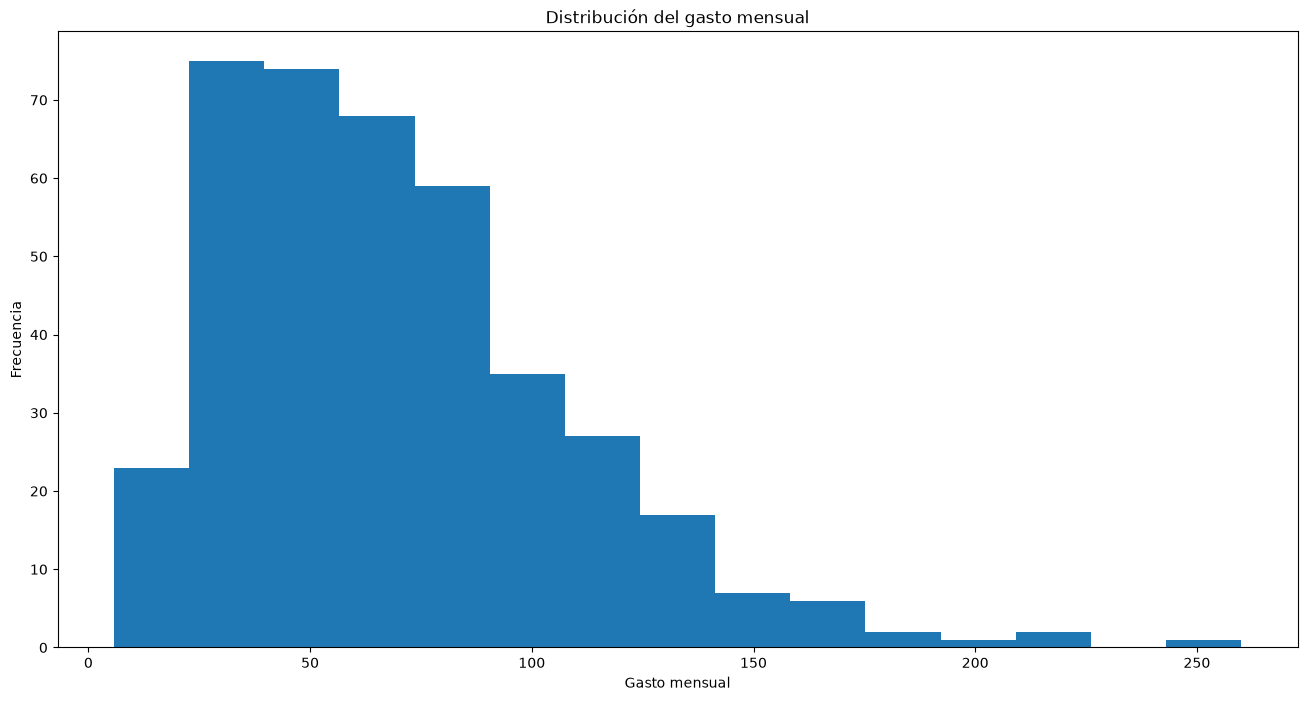

In [95]:
# TODO: crea el histograma de gasto_mensual
plt.figure(figsize=(16, 8))

plt.hist(df['gasto_mensual'], bins=15)

plt.xlabel("Gasto mensual")
plt.ylabel("Frecuencia")
plt.title("Distribución del gasto mensual")

plt.show()

### Interpreta

1. ¿Dónde parece concentrarse la mayoría de los clientes?
2. ¿La distribución parece aproximadamente simétrica?
3. ¿Existe una cola hacia valores altos o bajos?
4. ¿Observas valores alejados del resto?

**Respuesta:**  
1. Entre 30 y 70
2. No, tiene asimetría positiva
3. Hacia valores altos
4. Sí, algunos llegan hasta 260

# Parte 4 - Boxplot y valores atípicos

## Ejercicio 4

Representa `gasto_mensual` mediante un boxplot. Trata adecuadamente los valores ausentes.

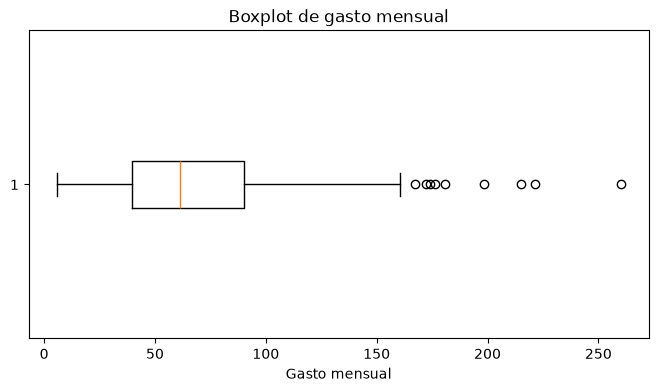

In [96]:
# TODO: crea un boxplot de gasto_mensual
plt.figure(figsize=(8,4))
plt.boxplot(df['gasto_mensual'].dropna(), orientation='horizontal')
plt.xlabel("Gasto mensual")
plt.title("Boxplot de gasto mensual")

plt.show()

### Interpreta

1. ¿Dónde se encuentra aproximadamente la mediana?
2. ¿Observas posibles outliers?
3. ¿Aparecen principalmente por encima o por debajo?
4. ¿Podemos afirmar que esos valores son errores únicamente observando el boxplot? Justifica.

**Respuesta:**  
1. Alrededor de 61
2. Sí, varios puntos aislados a la derecha
3. Por encima
4. No, pueden ser clientes reales que gastan mucho más que la media

# Parte 5 - Detectar outliers mediante IQR

## Ejercicio 5

Calcula:

$$
IQR=Q_3-Q_1
$$

y:

$$
L_{inferior}=Q_1-1.5IQR
$$

$$
L_{superior}=Q_3+1.5IQR
$$

Después localiza los clientes cuyo `gasto_mensual` esté fuera de estos límites y guarda el resultado en `outliers_gasto`.

In [97]:
# TODO: calcula Q1, Q3 e IQR
Q1 = df['gasto_mensual'].quantile(0.25)
Q2 = df['gasto_mensual'].quantile(0.50)
Q3 = df['gasto_mensual'].quantile(0.75)

IQR = Q3 - Q1

# TODO: calcula los límites inferior y superior
l_inf = Q1 - 1.5 * IQR
l_sup = Q3 + 1.5 * IQR

# TODO: muestra los resultados
print(f"IQR: {IQR:.2f}, Linferior: {l_inf:.2f}, Lsuperior: {l_sup:.2f}")

IQR: 50.43, Linferior: -35.93, Lsuperior: 165.80


C:\Users\aleja\AppData\Local\Temp\ipykernel_8356\559141648.py:3: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(df['edad'].dropna(), vert=False)


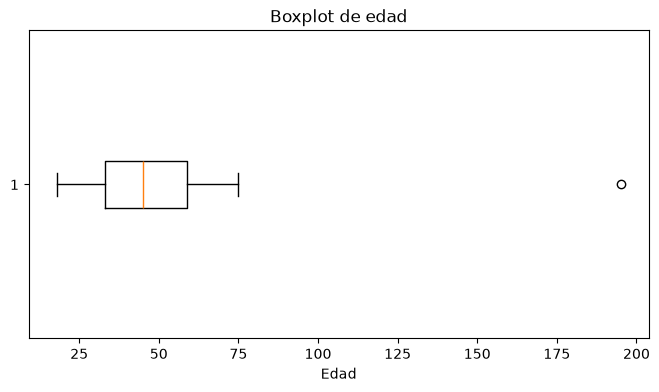

IQR: 26.00, Linferior: -6.00, Lsuperior: 98.00


In [98]:
# TODO: crea un boxplot de edad
plt.figure(figsize=(8, 4))
plt.boxplot(df['edad'].dropna(), vert=False)

plt.xlabel("Edad")
plt.title("Boxplot de edad")

plt.show()

# TODO: calcula Q1, Q3 e IQR
Q1_edad = df['edad'].quantile(0.25)
Q2_edad = df['edad'].quantile(0.50)
Q3_edad = df['edad'].quantile(0.75)

IQR_edad = Q3_edad - Q1_edad

# TODO: calcula los límites inferior y superior
l_inf_edad = Q1_edad - 1.5 * IQR_edad
l_sup_edad = Q3_edad + 1.5 * IQR_edad

# TODO: muestra los resultados
print(f"IQR: {IQR_edad:.2f}, Linferior: {l_inf_edad:.2f}, Lsuperior: {l_sup_edad:.2f}")

In [99]:
# TODO: crea outliers_gasto
filtro = (df['gasto_mensual'] < l_inf) | (df['gasto_mensual'] > l_sup)

outliers_gasto = df[filtro]

# TODO: muestra los posibles outliers
outliers_gasto

,cliente_id,edad,antiguedad_meses,ingresos_anuales,gasto_mensual,num_compras,devoluciones,dispositivo,zona,nivel_fidelidad,satisfaccion,compra_proximo_mes
50,20051,75,49.0,22908.36,176.52,3,1,Móvil,Este,Oro,3,Sí
68,20069,29,78.0,33382.86,215.30,8,2,Móvil,Centro,Bronce,4,No
202,20203,45,57.0,24727.71,167.26,7,4,Móvil,Norte,Platino,1,Sí
203,20204,25,41.0,39329.38,173.91,6,0,Ordenador,Norte,Bronce,2,Sí
207,20208,41,65.0,25812.18,221.59,10,0,Ordenador,Centro,Plata,5,Sí
268,20269,21,61.0,34737.20,198.28,7,2,Tablet,Centro,Bronce,3,Sí
292,20293,20,94.0,31714.55,172.31,13,0,Tablet,Este,Bronce,3,Sí
318,20319,56,38.0,9000.00,180.60,4,0,Ordenador,Este,Bronce,2,Sí
398,20399,75,85.0,40391.73,260.00,10,1,Móvil,Oeste,Bronce,4,Sí


### Responde

1. ¿Cuántos posibles outliers has encontrado?
2. ¿Qué porcentaje representan?
3. ¿Cuál es el mayor `gasto_mensual`?
4. ¿Eliminarías automáticamente estas observaciones?
5. ¿Qué investigarías antes?

**Respuesta:**  
1. 9
2. 2.25% (sobre 400 muestras, o 2.27% sobre los 397 valores válidos)
3. 260.00
4. No
5. Si son clientes reales con un gasto muy alto revisando su `num_compras`, `nivel_fidelidad` o `ingresos_anuales`, o si son errores de registro

# Parte 6 - Comparar varias distribuciones

## Ejercicio 6

Analiza:

- `edad`
- `ingresos_anuales`
- `gasto_mensual`
- `num_compras`
- `devoluciones`

Consulta sus estadísticas descriptivas y crea un histograma independiente para cada variable.

In [100]:
# TODO: consulta las estadísticas descriptivas de las variables indicadas
columnas = ['edad', 'ingresos_anuales', 'gasto_mensual', 'num_compras', 'devoluciones']
df[columnas].describe()

,edad,ingresos_anuales,gasto_mensual,num_compras,devoluciones
count,400.000000,396.000000,397.000000,400.000000,400.000000
mean,46.402500,36440.920379,69.089320,8.225000,1.225000
std,18.007809,14325.228166,39.023238,2.780955,1.136929
min,18.000000,9000.000000,5.770000,2.000000,0.000000
25%,33.000000,26034.092500,39.720000,6.000000,0.000000
50%,45.000000,36817.275000,61.170000,8.000000,1.000000
75%,59.000000,45969.032500,90.150000,10.000000,2.000000
max,195.000000,82925.370000,260.000000,17.000000,5.000000


In [101]:
# TODO: calcula sus medianas
df[columnas].median()

edad                   45.000
ingresos_anuales    36817.275
gasto_mensual          61.170
num_compras             8.000
devoluciones            1.000
dtype: float64

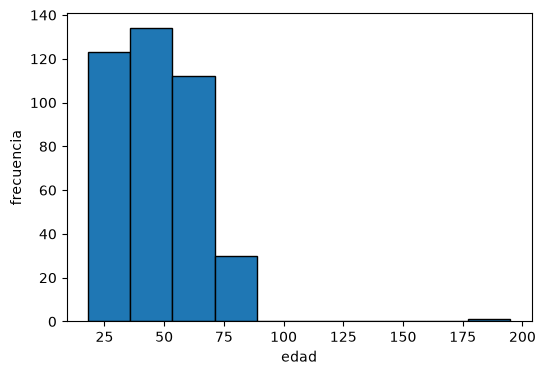

In [102]:
# TODO: histograma de edad
plt.figure(figsize=(6, 4))
plt.hist(df['edad'], edgecolor='black')
plt.xlabel('edad')
plt.ylabel('frecuencia')
plt.show()

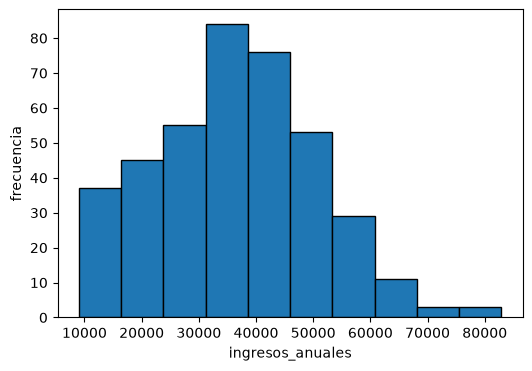

In [103]:
# TODO: histograma de ingresos_anuales
plt.figure(figsize=(6, 4))
plt.hist(df['ingresos_anuales'], edgecolor='black')
plt.xlabel('ingresos_anuales')
plt.ylabel('frecuencia')
plt.show()

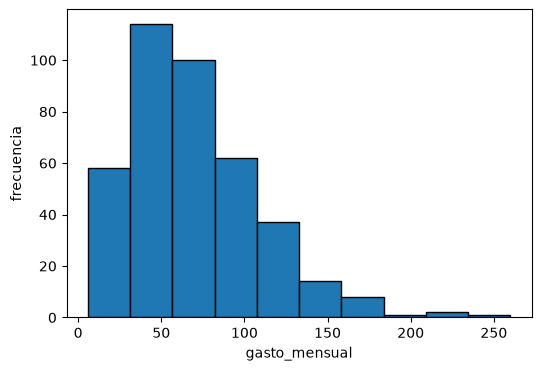

In [104]:
# TODO: histograma de gasto_mensual
plt.figure(figsize=(6, 4))
plt.hist(df['gasto_mensual'], edgecolor='black')
plt.xlabel('gasto_mensual')
plt.ylabel('frecuencia')
plt.show()

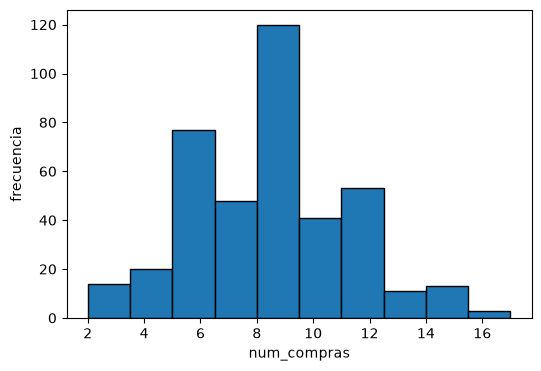

In [105]:
# TODO: histograma de num_compras
plt.figure(figsize=(6, 4))
plt.hist(df['num_compras'], edgecolor='black')
plt.xlabel('num_compras')
plt.ylabel('frecuencia')
plt.show()

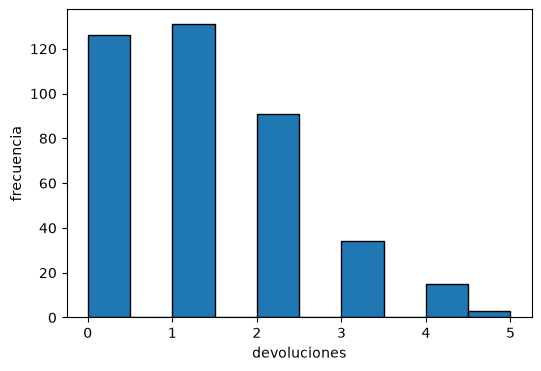

In [106]:
# TODO: histograma de devoluciones
plt.figure(figsize=(6, 4))
plt.hist(df['devoluciones'], edgecolor='black')
plt.xlabel('devoluciones')
plt.ylabel('frecuencia')
plt.show()

### Completa

| Variable | Media | Mediana | Mínimo | Máximo | Observación relevante |
|---|---:|---:|---:|---:|---|
| edad | 46.40 | 45.00 | 18.00 | 195.00 | Tiene un valor atípico imposible de 195 |
| ingresos_anuales | 36440.92 | 36817.28 | 9000.00 | 82925.37 | Distribución bastante simétrica con 4 nulos |
| gasto_mensual | 69.09 | 61.17 | 5.77 | 260.00 | Asimetría positiva con cola a la derecha y 3 nulos |
| num_compras | 8.23 | 8.00 | 2.00 | 17.00 | Campana simétrica centrada en 8 compras |
| devoluciones | 1.23 | 1.00 | 0.00 | 5.00 | El 75% hace 2 o menos devoluciones |

### Busca una observación sospechosa

- ¿Qué variable es?
- ¿Qué valor tiene?
- ¿Por qué parece sospechoso?
- ¿Es un outlier?
- ¿Podemos afirmar directamente que es un error?
- ¿Qué harías antes de modificarlo?

**Respuesta:**  
- `edad`
- 195
- Es imposible que un cliente tenga 195 años
- Sí, supera el límite superior del IQR (98)
- Biológicamente es un error, pero a nivel estadístico conviene revisar el registro completo
- Revisaría el resto de columnas de esa fila para ver si es un cliente válido con un fallo tipográfico y decidir si imputarlo como `NaN` o descartar la fila

# Parte 7 - Variables categóricas

## Ejercicio 7 - Frecuencias

Analiza `dispositivo`, `zona`, `nivel_fidelidad` y `compra_proximo_mes`.

Calcula frecuencias absolutas, relativas y porcentajes mediante `value_counts()`.

In [107]:
# TODO: analiza dispositivo
pd.DataFrame({
    'Absoluta': df['dispositivo'].value_counts(),
    'Relativa': df['dispositivo'].value_counts(normalize=True),
    'Porcentaje': df['dispositivo'].value_counts(normalize=True) * 100
})

,Absoluta,Relativa,Porcentaje
dispositivo,,,
Móvil,242,0.6050,60.50
Ordenador,133,0.3325,33.25
Tablet,25,0.0625,6.25


In [108]:
# TODO: analiza zona
pd.DataFrame({
    'Absoluta': df['zona'].value_counts(),
    'Relativa': df['zona'].value_counts(normalize=True),
    'Porcentaje': df['zona'].value_counts(normalize=True) * 100
})

,Absoluta,Relativa,Porcentaje
zona,,,
Este,89,0.2225,22.25
Sur,80,0.2000,20.00
Norte,79,0.1975,19.75
Oeste,76,0.1900,19.00
Centro,76,0.1900,19.00


In [109]:
# TODO: analiza nivel_fidelidad
pd.DataFrame({
    'Absoluta': df['nivel_fidelidad'].value_counts(),
    'Relativa': df['nivel_fidelidad'].value_counts(normalize=True),
    'Porcentaje': df['nivel_fidelidad'].value_counts(normalize=True) * 100
})

,Absoluta,Relativa,Porcentaje
nivel_fidelidad,,,
Bronce,162,0.4050,40.50
Plata,105,0.2625,26.25
Oro,83,0.2075,20.75
Platino,50,0.1250,12.50


In [110]:
# TODO: analiza compra_proximo_mes
pd.DataFrame({
    'Absoluta': df['compra_proximo_mes'].value_counts(),
    'Relativa': df['compra_proximo_mes'].value_counts(normalize=True),
    'Porcentaje': df['compra_proximo_mes'].value_counts(normalize=True) * 100
})

,Absoluta,Relativa,Porcentaje
compra_proximo_mes,,,
No,246,0.615,61.5
Sí,154,0.385,38.5


### Completa

| Variable | Categoría más frecuente | Nº muestras | Porcentaje |
| :--- | :--- | :--- | :--- |
| dispositivo | Móvil | 242 | 60.50% |
| zona | Este | 89 | 22.25% |
| nivel_fidelidad | Bronce | 162 | 40.50% |
| compra_proximo_mes | No | 246 | 61.50% |

# Parte 8 - Visualización de variables categóricas

## Ejercicio 8

Crea gráficos de barras independientes para:

- `dispositivo`
- `nivel_fidelidad`
- `compra_proximo_mes`

Todos deben incluir título y etiquetas.

Text(0.5, 0, '')

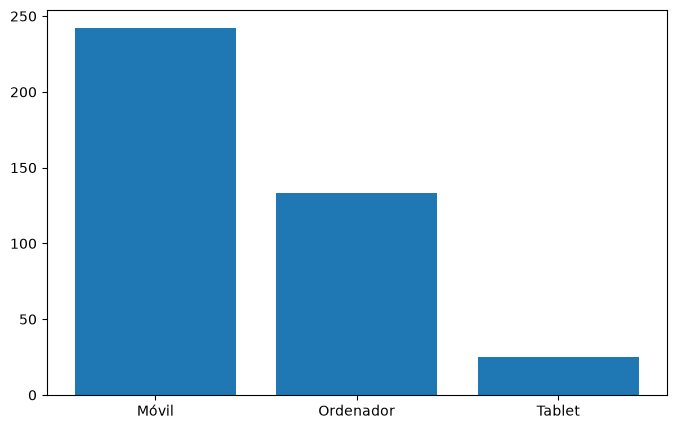

In [111]:
# TODO: gráfico de barras de dispositivo
conteos_disp = df['dispositivo'].value_counts()

plt.figure(figsize=(8,5))
plt.bar(conteos_disp.index, conteos_disp.values)
plt.xlabel("")
plt.xlabel("")

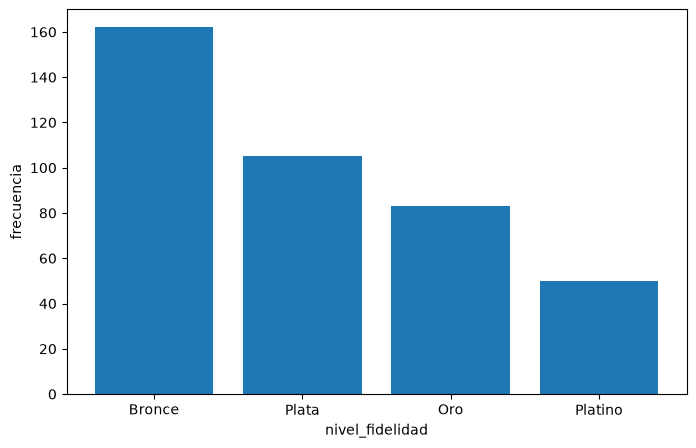

In [112]:
# TODO: gráfico de barras de nivel_fidelidad
conteos_fid = df['nivel_fidelidad'].value_counts()

plt.figure(figsize=(8, 5))
plt.bar(conteos_fid.index, conteos_fid.values)

plt.xlabel('nivel_fidelidad')
plt.ylabel('frecuencia')
plt.show()

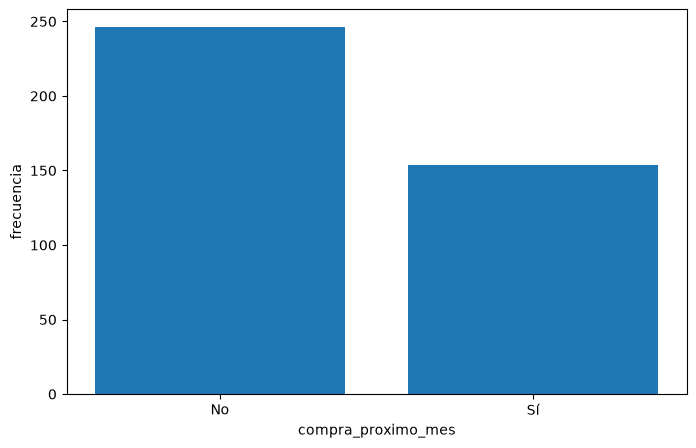

In [113]:
# TODO: gráfico de barras de compra_proximo_mes
conteos_prox = df['compra_proximo_mes'].value_counts()

plt.figure(figsize=(8, 5))
plt.bar(conteos_prox.index.astype(str), conteos_prox.values)

plt.xlabel('compra_proximo_mes')
plt.ylabel('frecuencia')
plt.show()

### Interpreta

Escribe al menos una conclusión sobre cada gráfico.

Para `compra_proximo_mes`, responde además:

> ¿Las clases están perfectamente equilibradas?

Justifica utilizando porcentajes.

**Respuesta:**  
- dispositivo: Móvil es el más utilizado (60.50%), mientras que tablet es el menos frecuente (6.25%)
- nivel_fidelidad: Destaca el nivel Bronce (40.50%), siendo Platino el más raro (12.50%)
- compra_proximo_mes: No están perfectamente equilibradas, ya que `No` representa el 61.50% y `Sí` el 38.50%

# Parte 9 - Relación entre dos variables numéricas

Queremos investigar:

> **¿Existe alguna relación entre el número de compras realizadas y el gasto mensual?**

## Ejercicio 9 - Scatter plot

Representa:

$$
X=\text{num\_compras}
$$

$$
Y=\text{gasto\_mensual}
$$

mediante un diagrama de dispersión.

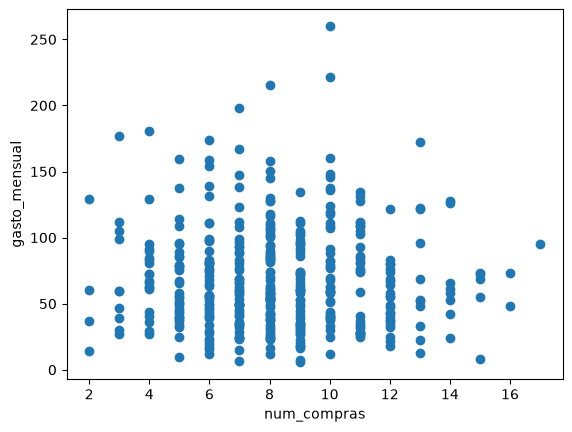

In [114]:
# TODO: crea un scatter plot de num_compras frente a gasto_mensual
plt.scatter(df['num_compras'], df['gasto_mensual'])
plt.xlabel('num_compras')
plt.ylabel('gasto_mensual')
plt.show()

### Antes de calcular la correlación

1. ¿Parece existir una relación?
2. ¿Parece positiva o negativa?
3. ¿Parece fuerte o débil?
4. ¿Observas muestras especialmente alejadas?

**Respuesta:**  
1. No tienen un patrón claro
2. Negativa
3. Muy débil
4. Algunos puntos superan los 200 de gasto mensual

# Parte 10 - Correlación

## Ejercicio 10

Calcula la correlación entre `num_compras` y `gasto_mensual` utilizando `corr()`.

In [115]:
# TODO: calcula la correlación entre num_compras y gasto_mensual
correlacion = df['num_compras'].corr(df['gasto_mensual'])
print(f"Correlación de Pearson (r): {correlacion}")

Correlación de Pearson (r): -0.014165499001183244


### Interpreta

1. ¿Cuál es el valor de \(r\)?
2. ¿Es positivo o negativo?
3. ¿Qué significa el signo?
4. ¿Coincide con lo observado en el scatter plot?
5. ¿Podemos afirmar que realizar más compras **provoca** un mayor gasto mensual? Justifica.

**Respuesta:**  
1. -0.014
2. Negativo (prácticamente 0)
3. Una relación lineal inversa casi nula
4. Sí, coincide con la nube de puntos dispersa sin tendencia clara
5. No, correlación no implica causalidad y además la relación lineal es casi cero

# Parte 11 - Matriz de correlaciones

## Ejercicio 11

Selecciona las variables numéricas y calcula su matriz de correlaciones.

> **Atención:** `cliente_id` es técnicamente numérico, pero conceptualmente es un identificador. No debes incluirlo.

In [116]:
# TODO: selecciona las variables numéricas excluyendo cliente_id
numericas = df.select_dtypes(include="number").drop(columns=['cliente_id'])

# TODO: calcula y muestra la matriz de correlaciones
correlaciones = numericas.corr()
correlaciones

,edad,antiguedad_meses,ingresos_anuales,gasto_mensual,num_compras,devoluciones,satisfaccion
edad,1.000000,0.031192,-0.036610,0.021361,-0.077583,-0.097102,-0.062801
antiguedad_meses,0.031192,1.000000,-0.058738,0.006482,-0.099965,-0.056458,-0.040051
ingresos_anuales,-0.036610,-0.058738,1.000000,-0.000367,0.072991,0.000260,-0.062595
gasto_mensual,0.021361,0.006482,-0.000367,1.000000,-0.014165,0.030674,-0.054523
num_compras,-0.077583,-0.099965,0.072991,-0.014165,1.000000,-0.005747,0.092211
devoluciones,-0.097102,-0.056458,0.000260,0.030674,-0.005747,1.000000,0.030817
satisfaccion,-0.062801,-0.040051,-0.062595,-0.054523,0.092211,0.030817,1.000000


### Interpreta

1. ¿Por qué todos los valores de la diagonal son 1?
2. ¿Por qué la matriz es simétrica?
3. Sin considerar la diagonal, ¿qué pareja presenta la correlación positiva más alta?
4. ¿Qué pareja presenta la correlación más negativa?
5. ¿Hay variables cuya correlación sea prácticamente cero?

**Respuesta:**  
1. Cada variable se compara consigo misma
2. La correlación entre A y B es la misma que entre B y A
3. num_compras y satisfaccion
4. antiguedad_meses y num_compras
5. Sí, ingresos_anuales con devoluciones y con gasto_mensual

# Parte 12 - Visualizar las correlaciones

## Ejercicio 12

Representa la matriz mediante `plt.imshow()`.

Añade nombres de variables en ambos ejes, barra de color y título.

range(0, 7)


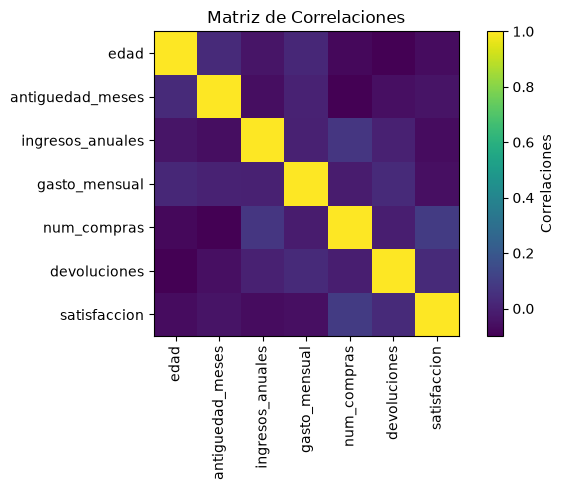

In [117]:
# TODO: representa la matriz de correlaciones con plt.imshow()
plt.figure(figsize=(7,5))
plt.imshow(correlaciones)

print(range(len(correlaciones.columns)))

plt.xticks(
    range(len(correlaciones.columns)), 
    correlaciones.columns,
    rotation= 90
)

plt.yticks(
    range(len(correlaciones.columns)), 
    correlaciones.columns
)

plt.colorbar(label="Correlaciones")
plt.title("Matriz de Correlaciones")

plt.tight_layout()
plt.show()

### Interpreta tres relaciones

Selecciona tres relaciones de la matriz y explica qué significa cada valor.

1. num_compras y satisfaccion (r = 0.092): correlación positiva muy débil
2. antiguedad_meses y num_compras (r = -0.100): correlación negativa muy débil
3. ingresos_anuales y gasto_mensual (r = -0.0004): correlación casi nula 

Recuerda:

$$
\boxed{\text{correlación}\neq\text{causalidad}}
$$

# Parte 13 - Variable numérica frente a categórica

Queremos investigar:

> **¿Los clientes que realizan una compra el mes siguiente presentan un gasto histórico diferente?**

## Ejercicio 13

Utiliza `groupby()` para obtener para cada valor de `compra_proximo_mes`:

- número de clientes
- gasto medio
- mediana
- desviación estándar.

In [118]:
# TODO: agrupa por compra_proximo_mes y calcula las estadísticas solicitadas
df.groupby('compra_proximo_mes')['gasto_mensual'].agg(
    numero_clientes = "count",
    gasto_medio = "mean",
    mediana = "median",
    desviacion_estandar = "std"
)

,numero_clientes,gasto_medio,mediana,desviacion_estandar
compra_proximo_mes,,,,
No,245,64.589469,59.28,33.693480
Sí,152,76.342368,66.50,45.534042


In [119]:
df.groupby('compra_proximo_mes')['ingresos_anuales'].agg(
    numero_clientes = "count",
    ingresos_medios = "mean",
    mediana = "median",
    desviacion_estandar = "std"
)

,numero_clientes,ingresos_medios,mediana,desviacion_estandar
compra_proximo_mes,,,,
No,245,36457.790449,36999.62,13983.264281
Sí,151,36413.548411,36715.09,14910.598296


In [120]:
df.groupby('nivel_fidelidad')['gasto_mensual'].agg(
    numero_clientes = "count",
    ingresos_medios = "mean",
    mediana = "median",
    desviacion_estandar = "std"
)

,numero_clientes,ingresos_medios,mediana,desviacion_estandar
nivel_fidelidad,,,,
Bronce,159,68.201321,57.79,42.580449
Oro,83,70.932410,63.31,37.513417
Plata,105,68.686095,62.79,37.078855
Platino,50,69.700400,68.06,34.328374


### Interpreta

1. ¿Qué grupo presenta mayor gasto medio?
2. ¿Y mayor mediana?
3. ¿Las diferencias parecen grandes o pequeñas?
4. ¿La media y la mediana cuentan exactamente la misma historia?

**Respuesta:**  
1. El grupo `Sí` (76.34 frente a 64.59)
2. También el grupo `Sí` (66.50 frente a 59.28)
3. Moderadas, aunque la diferencia es mayor en la media (11.75) que en la mediana (7.22)
4. Sí, ambos indican mayor gasto en los que compran, aunque la media sube más por los valores altos (outliers) del grupo `Sí`

# Parte 14 - Comparación visual entre grupos

## Ejercicio 14

Crea:

- `grupo_no`: gasto mensual de quienes no compran el mes siguiente
- `grupo_si`: gasto mensual de quienes sí compran.

Representa ambos mediante un único boxplot.

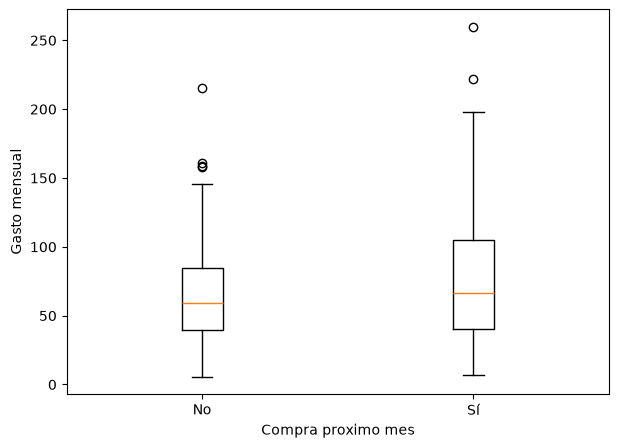

In [121]:
# TODO: crea grupo_no y grupo_si
grupo_no = df.loc[df['compra_proximo_mes'] == 'No', "gasto_mensual"].dropna()
grupo_si = df.loc[df['compra_proximo_mes'] == 'Sí', "gasto_mensual"].dropna()

# TODO: representa ambos grupos mediante un boxplot
plt.figure(figsize=(7,5))
plt.boxplot([grupo_no, grupo_si], tick_labels=['No', 'Sí'])

plt.xlabel("Compra proximo mes")
plt.ylabel("Gasto mensual")
plt.show()


### Interpreta

1. ¿Qué grupo presenta una mediana mayor?
2. ¿Cuál parece tener mayor dispersión?
3. ¿Existen outliers en ambos?
4. ¿El gráfico apoya las conclusiones obtenidas mediante `groupby()`?

**Respuesta:**  
1. El grupo `Sí` (la línea naranja está más arriba, alrededor de 66.5 frente a 59.3)
2. El grupo `Sí`, tanto su caja (IQR) como su bigote superior son más alargados
3. Sí, ambos muestran puntos aislados por encima del bigote superior
4. Sí, se ve que el grupo `Sí` tiene una mediana algo superior, mayor dispersión y valores extremos más altos

# Parte 15 - Dos variables categóricas

Queremos responder:

> **¿La proporción de compra es igual para todos los niveles de fidelidad?**

## Ejercicio 15

Crea:

1. una tabla de contingencia con frecuencias absolutas
2. una tabla normalizada por filas mediante `normalize="index"`
3. una versión expresada en porcentajes.

In [122]:
# TODO: tabla de contingencia con frecuencias absolutas
frecuencias = pd.crosstab(df['nivel_fidelidad'], df['compra_proximo_mes'])
frecuencias

compra_proximo_mes,No,Sí
nivel_fidelidad,,
Bronce,112,50
Oro,52,31
Plata,63,42
Platino,19,31


In [123]:
# TODO: tabla normalizada por filas
frecuencias = pd.crosstab(df['nivel_fidelidad'], df['compra_proximo_mes'], normalize="index")
frecuencias

compra_proximo_mes,No,Sí
nivel_fidelidad,,
Bronce,0.691358,0.308642
Oro,0.626506,0.373494
Plata,0.600000,0.400000
Platino,0.380000,0.620000


In [124]:
# TODO: muestra las proporciones como porcentajes
(frecuencias * 100).round(2)

compra_proximo_mes,No,Sí
nivel_fidelidad,,
Bronce,69.14,30.86
Oro,62.65,37.35
Plata,60.00,40.00
Platino,38.00,62.00


### Interpreta

1. ¿Qué nivel tiene mayor número absoluto de clientes que compran?
2. ¿Qué nivel tiene mayor porcentaje de clientes que compran?
3. ¿Coinciden necesariamente ambas respuestas?
4. ¿Por qué son importantes las proporciones cuando los grupos tienen tamaños diferentes?

**Respuesta:**  
1. Bronce (con 50 clientes)
2. Platino (con un 62.00%)
3. No
4. Porque un grupo muy numeroso puede tener más casos en total aunque su tasa real de compra sea baja; normalizar a porcentajes permite comparar grupos de distinto tamaño en igualdad de condiciones

# Parte 16 - Correlación no implica causalidad

## Ejercicio 16 - Razonamiento

Un compañero observa una relación entre `nivel_fidelidad` y `compra_proximo_mes` y afirma:

> **«Subir a un cliente al nivel Platino hará que compre el próximo mes».**

¿Es correcta esta conclusión?

Redacta entre **5 y 8 líneas** utilizando correctamente:

- asociación
- causalidad
- variables adicionales
- evidencia

### Respuesta
- La conclusión no es correcta porque confunde asociación con causalidad. Los datos muestran una clara asociación entre `nivel_fidelidad` y `compra_proximo_mes`, ya que los clientes Platino compran en un 62% frente al 30.86% de Bronce.
Sin embargo, esta evidencia observacional no demuestra que ascender de nivel provoque directamente la compra.
Es muy probable que existan variables adicionales detrás, como el hábito previo de compra o la vinculación con la tienda, que expliquen tanto alcanzar el nivel Platino como volver a comprar.
Por tanto, cambiar la etiqueta de nivel de un cliente por sí solo no garantiza que compre el mes siguiente.

# Parte 17 - Investiga una hipótesis

## Ejercicio 17

Elige **una**:

**A.** **¿Los clientes con mayores ingresos gastan más mensualmente?**  
**B.** ¿Los clientes más antiguos realizan más compras?  
**C.** ¿La satisfacción está relacionada con el número de compras?  
**D.** ¿El número de devoluciones está relacionado con la satisfacción?

Realiza:

1. selección de variables
2. estadística descriptiva
3. visualización adecuada
4. correlación si procede
5. interpretación.

       ingresos_anuales  gasto_mensual
count        396.000000     397.000000
mean       36440.920379      69.089320
std        14325.228166      39.023238
min         9000.000000       5.770000
25%        26034.092500      39.720000
50%        36817.275000      61.170000
75%        45969.032500      90.150000
max        82925.370000     260.000000


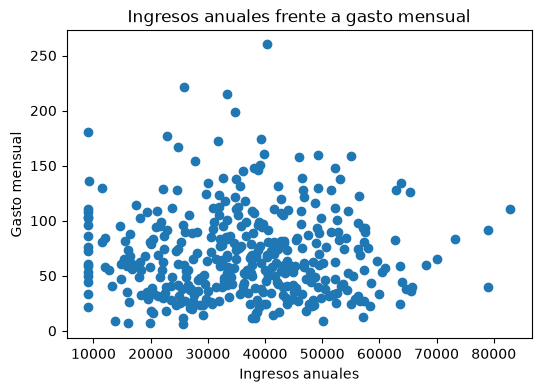

Correlación r: -0.0004


In [125]:
# TODO: desarrolla aquí el análisis de la hipótesis seleccionada
vars_hip = ['ingresos_anuales', 'gasto_mensual']
print(df[vars_hip].describe())

plt.figure(figsize=(6, 4))
plt.scatter(df['ingresos_anuales'], df['gasto_mensual'])
plt.title("Ingresos anuales frente a gasto mensual")
plt.xlabel("Ingresos anuales")
plt.ylabel("Gasto mensual")
plt.show()

r_hip = df['ingresos_anuales'].corr(df['gasto_mensual'])
print("Correlación r:", round(r_hip, 4))

### Conclusión de la hipótesis

Con los datos analizados se descarta la hipótesis **A**: los clientes con mayores ingresos no gastan más mensualmente en la plataforma.
Mientras que `ingresos_anuales` presenta una media de 36.440,92 € (mediana 36.817,28 €) y `gasto_mensual` una media de 69,09 € (mediana 61,17 €), el diagrama de dispersión muestra una nube totalmente horizontal sin tendencia creciente ni decreciente.
De hecho, se observa incluso una concentración vertical en el mínimo de 9.000 € con gastos muy variados, y clientes con ingresos altos (más de 60.000 €) mantienen gastos moderados.
Esto queda respaldado por una correlación lineal prácticamente nula (`r = -0.0004`), por lo que el nivel de ingresos no parece asociarse con el gasto mensual.

# Parte 18 - El reto del analista

## Ejercicio 18

Trabaja ahora con mayor autonomía:

> **¿Qué características parecen diferenciar a los clientes que compran el mes siguiente de los que no compran?**

Puedes investigar:

`edad`, `antiguedad_meses`, `ingresos_anuales`, `gasto_mensual`, `num_compras`, `devoluciones`, `dispositivo`, `zona`, `nivel_fidelidad` y `satisfaccion`.

Tu análisis debe contener como mínimo:

- una comparación numérica
- una comparación categórica
- dos visualizaciones
- estadísticas descriptivas
- una tabla de proporciones.

In [126]:
# TODO: comparación numérica
num_reto = ['edad', 'antiguedad_meses', 'ingresos_anuales', 'gasto_mensual', 'num_compras', 'devoluciones', 'satisfaccion']
df.groupby('compra_proximo_mes')[vars_num_reto].agg(['mean', 'median', 'std']).round(2)

edad               antiguedad_meses                \
                     mean median    std             mean median    std   
compra_proximo_mes                                                       
No                  47.81   47.5  18.42            59.47   59.0  34.88   
Sí                  44.15   44.0  17.16            60.46   60.5  32.94   

                   ingresos_anuales                     gasto_mensual  ...  \
                               mean    median       std          mean  ...   
compra_proximo_mes                                                     ...   
No                         36457.79  36999.62  13983.26         64.59  ...   
Sí                         36413.55  36715.09  14910.60         76.34  ...   

                          num_compras              devoluciones               \
                      std        mean median   std         mean median   std   
compra_proximo_mes                                                             
No                  33.69        8.15    8.0  2.88         1.29    1.0  1.17   
Sí                  45.53        8.35    8.0  2.62         1.12    1.0  1.08   

                   satisfaccion               
                           mean median   std  
compra_proximo_mes                            
No                         3.28    3.0  1.18  
Sí                         3.40    3.0  1.14  

[2 rows x 21 columns]

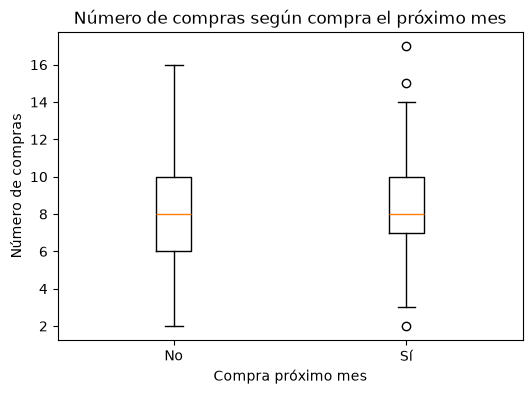

In [127]:
# TODO: primera visualización
compras_no = df.loc[df['compra_proximo_mes'] == 'No', 'num_compras'].dropna()
compras_si = df.loc[df['compra_proximo_mes'] == 'Sí', 'num_compras'].dropna()

plt.figure(figsize=(6, 4))
plt.boxplot([compras_no, compras_si], tick_labels=['No', 'Sí'])
plt.title("Número de compras según compra el próximo mes")
plt.xlabel("Compra próximo mes")
plt.ylabel("Número de compras")
plt.show()

In [128]:
# TODO: comparación categórica y tabla de proporciones
prop_disp = (pd.crosstab(df['dispositivo'], df['compra_proximo_mes'], normalize='index') * 100).round(2)
prop_zona = (pd.crosstab(df['zona'], df['compra_proximo_mes'], normalize='index') * 100).round(2)
prop_fid = (pd.crosstab(df['nivel_fidelidad'], df['compra_proximo_mes'], normalize='index') * 100).round(2)

print(prop_disp)
print(prop_zona)
print(prop_fid)

compra_proximo_mes     No     Sí
dispositivo                     
Móvil               63.22  36.78
Ordenador           57.89  42.11
Tablet              64.00  36.00
compra_proximo_mes     No     Sí
zona                            
Centro              63.16  36.84
Este                64.04  35.96
Norte               54.43  45.57
Oeste               57.89  42.11
Sur                 67.50  32.50
compra_proximo_mes     No     Sí
nivel_fidelidad                 
Bronce              69.14  30.86
Oro                 62.65  37.35
Plata               60.00  40.00
Platino             38.00  62.00


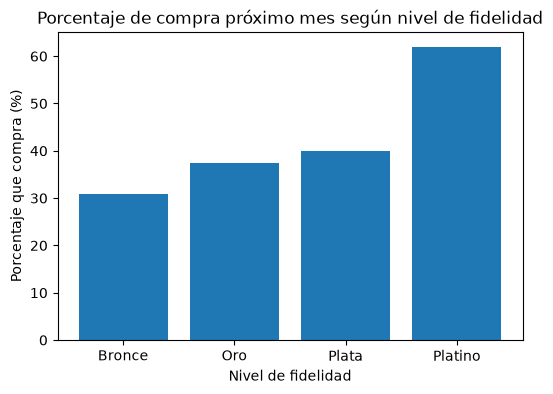

: 

In [ ]:
# TODO: segunda visualización
plt.figure(figsize=(6, 4))
plt.bar(prop_fid.index, prop_fid['Sí'])
plt.title("Porcentaje de compra próximo mes según nivel de fidelidad")
plt.xlabel("Nivel de fidelidad")
plt.ylabel("Porcentaje que compra (%)")
plt.show()

### Interpretación del reto

Resume qué características parecen diferenciar a ambos grupos.

Distingue entre:

- lo que **observas** en el dataset
- lo que **no puedes concluir** a partir de esos datos.

**Respuesta:**  
- **Lo que observo en el dataset:** las principales diferencias están en `nivel_fidelidad` (el 62% de los Platino compra frente al 30.86% de Bronce) y en `gasto_mensual` (mediana de 66.50 € frente a 59.28 €), además de una edad algo menor (mediana de 44 frente a 47.5 años) y mayor tasa en ordenador (42.11%) y zona Norte (45.57%), mientras que ingresos, número de compras, devoluciones y satisfacción apenas cambian
- **Lo que no puedo concluir a partir de estos datos:** no se puede afirmar que ninguna de estas variables sea la causa directa de que el cliente vuelva a comprar, ya que son datos observacionales y pueden influir otros factores externos no medidos

## Ejercicio 19

Selecciona los **5 hallazgos más relevantes**.

Para cada uno indica:

- **Pregunta:** ¿qué queríamos averiguar?
- **Evidencia:** ¿qué estadística, tabla o gráfico lo respalda?
- **Interpretación:** ¿qué hemos observado?
- **Limitación:** ¿qué no podemos concluir?

### Hallazgo 1
**Pregunta:** ¿Cómo se distribuye el gasto mensual de los clientes y existen valores extremos?  
**Evidencia:** `describe()` (media 69.09 € vs. mediana 61.17 €), histograma, boxplot y regla del IQR (`L_superior = 165.80 €`), detectando 9 outliers hasta 260.00 €.  
**Interpretación:** La distribución tiene asimetría positiva; la mayoría se concentra entre 39.72 € y 90.15 €, pero un 2.25% gasta mucho más que la media.  
**Limitación:** Que sean outliers estadísticos no prueba que sean errores; pueden ser clientes reales de alto consumo.

### Hallazgo 2
**Pregunta:** ¿Existen datos erróneos o ausentes que afecten a la calidad del dataset?  
**Evidencia:** `info()` (12 nulos: 5 en `antiguedad_meses`, 4 en `ingresos_anuales`, 3 en `gasto_mensual`) y el boxplot/IQR de `edad`, que aísla al cliente `20138` con 195 años.  
**Interpretación:** El dataset está bastante completo (máximo 1.25% de nulos en una columna), pero contiene un error claro de registro en `edad`.  
**Limitación:** No podemos saber solo con los datos si fue un fallo tipográfico (por ejemplo 95 o 19) ni borrar la fila sin revisar el resto de sus atributos.

### Hallazgo 3
**Pregunta:** ¿Los clientes con mayores ingresos o que realizan más pedidos gastan más al mes?  
**Evidencia:** Diagramas de dispersión y matriz de correlaciones (`r = -0.0004` entre `ingresos_anuales` y `gasto_mensual`; `r = -0.014` entre `num_compras` y `gasto_mensual`).  
**Interpretación:** Las nubes de puntos son totalmente dispersas y no existe relación lineal entre ingresos, número de compras y gasto mensual.  
**Limitación:** La correlación de Pearson solo mide relaciones lineales y no descarta patrones no lineales ni explica los motivos de compra.

### Hallazgo 4
**Pregunta:** ¿El gasto histórico es distinto entre quienes compran el próximo mes y quienes no?  
**Evidencia:** Tabla `groupby('compra_proximo_mes')['gasto_mensual']` y boxplot comparativo (`Sí`: media 76.34 €, mediana 66.50 € vs. `No`: media 64.59 €, mediana 59.28 €).  
**Interpretación:** Los clientes que vuelven a comprar presentan un gasto histórico moderadamente superior, mayor dispersión y outliers más altos.  
**Limitación:** Existe mucho solapamiento entre ambos grupos, por lo que el gasto por sí solo no basta para clasificar perfectamente a un cliente.

### Hallazgo 5
**Pregunta:** ¿La tasa de compra el próximo mes varía según el nivel de fidelidad?  
**Evidencia:** Tabla de contingencia `crosstab(..., normalize='index')` y gráfico de barras: Platino compra en un 62.00%, Plata en un 40.00%, Oro en un 37.35% y Bronce en un 30.86%.  
**Interpretación:** Aunque Bronce aporta más compradores en números absolutos (50) por ser el grupo mayoritario (40.50%), Platino duplica su proporción de compra.  
**Limitación:** Asociación no implica causalidad; ascender manualmente a un cliente a Platino no garantiza que compre el mes siguiente.

# Parte 20 - Conclusiones

## Ejercicio 20

Redacta unas conclusiones finales de entre **10 y 15 líneas**.

Incluye:

- características generales del dataset
- principales distribuciones
- posibles valores atípicos
- relaciones encontradas
- correlaciones relevantes
- diferencias entre grupos
- algún resultado que te haya sorprendido
- posibles problemas de calidad
- qué investigarías a continuación.

### Conclusiones

El dataset `clientes_ecommerce.csv` reúne 400 muestras y 12 columnas (10 features útiles tras descartar `cliente_id` y separar `compra_proximo_mes`), presentando un ligero desbalanceo en el target (`No` 61.50% vs. `Sí` 38.50%).
En las distribuciones destacan un claro predominio del móvil (60.50%) y del nivel Bronce (40.50%), una campana simétrica en `num_compras` (mediana 8) y una asimetría positiva en `gasto_mensual` (media 69.09 €, mediana 61.17 €).
Mediante el criterio del IQR detectamos 9 valores atípicos altos en `gasto_mensual` (hasta 260 €) y un error evidente de calidad en `edad` con un registro de 195 años, además de 12 valores ausentes repartidos entre antigüedad, ingresos y gasto.
Sorprendentemente, las variables numéricas muestran correlaciones lineales prácticamente nulas entre sí, destacando que ni los ingresos (`r = -0.0004`) ni el número de compras (`r = -0.014`) se asocian con un mayor gasto mensual.
Al comparar grupos según el target, las mayores diferencias aparecen en `nivel_fidelidad` (62.00% de compra en Platino frente al 30.86% en Bronce) y en `gasto_mensual` (mediana de 66.50 € frente a 59.28 €).
Como siguientes pasos, imputaría los nulos, decidiría cómo tratar el outlier de `edad` y codificaría las variables categóricas para entrenar un primer modelo de clasificación.

# Antes de entregar

Comprueba que:

- [ ] Has completado todos los ejercicios.
- [ ] Has respondido las preguntas en Markdown.
- [ ] Todos los gráficos tienen título.
- [ ] Los ejes están correctamente identificados.
- [ ] Has interpretado los resultados.
- [ ] Has diferenciado correlación de causalidad.
- [ ] No has eliminado automáticamente los outliers.
- [ ] Has ejecutado el notebook completo desde el principio sin errores.

**Nombre recomendado:** `Practica_05_Apellido_Nombre.ipynb`